# 第 0 课：什么是世界模型？——在弹球世界里亲手做一个

这节课你会亲手完成三件事：

1. **学**：让一个神经网络看大量"小球怎么动"的数据，自己学会这个世界的物理规律。这个网络就是**世界模型**。
2. **做梦**：只给世界模型一个起点和一串动作，让它自己往后想象很多步，看看它想得准不准。
3. **规划**：让智能体**只靠世界模型**在脑子里试动作，把小球推到目标点。

**用到的知识**：只有你已经会的东西——全连接网络（MLP）、均方误差（MSE）、Adam 优化器。

**运行时间**：CPU 上不到 1 分钟。

> 建议先读同目录的讲义 [README.md](README.md) 第 1–3 节，再从上到下运行这个 notebook。

## 0. 准备

下面这个格子集中放了练习要改的参数。第一次运行先别动，跑完整个 notebook、读完讲义后，再按练习题回来改。

In [1]:
SEED = 0                  ## 随机种子：换一个数字就换一批随机数据，可以用来检查结论稳不稳
PREDICT_DELTA = True      ## 练习 1：改成 False，让模型直接预测下一个状态 s'，而不是变化量 Δs
NORMALIZE = True          ## 练习 2：改成 False，关掉输入输出的标准化
TRAIN_SPEED_LIMIT = None  ## 练习 4：比如改成 1.0，训练时只用速度不超过 1 的数据
K, H = 500, 20            ## 练习 5：规划时每一步在脑子里试 K 条动作序列，每条往前想 H 步

In [2]:
import time
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

T_START = time.time()     ## 记录整个 notebook 的运行时间
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams['figure.dpi'] = 100
print(f'torch {torch.__version__}, numpy {np.__version__}, 设备: {device}')

torch 2.14.0+cu130, numpy 2.4.6, 设备: cpu


## 1. 一个真实的小世界：BallWorld

世界是一个 $[-1,1]\times[-1,1]$ 的方盒子，里面有一个小球（看成一个点）。

- **状态** $s=(x, y, v_x, v_y)$：位置和速度。只知道位置是不够的——同一个位置，往左飞和往右飞，下一步会去完全不同的地方。
- **动作** $a=(a_x, a_y)$：每一步可以推小球一下，每个分量在 $[-1,1]$ 之间。
- **物理规律**（每一步时长 $\Delta t=0.1$）：
  - 速度：$v \leftarrow v + \Delta t\,(2a - v)$，推力让它加速，阻力让它减速；
  - 位置：$p \leftarrow p + \Delta t\, v$；
  - 碰墙：像镜子一样反射回来，撞墙方向的速度反向（弹性碰撞，不损失速度）。

这套规律有两个性质，后面会用到：

- 速度永远不超过 2，所以每一步最多走 0.2；
- 除了碰墙那一下，其他时候规律都是**线性**的。碰墙是整个世界里唯一"拐弯"的地方。

**重要**：世界模型**看不到**这些公式，它只能看到数据。我们写出公式，只是为了造一个"真实世界"来产生数据、检验模型。

In [3]:
DT, DRAG, ACC = 0.1, 1.0, 2.0   ## 时间步长、阻力系数、推力系数
V_MAX = ACC / DRAG               ## 速度上限：推力和阻力平衡时的速度，等于 2

def env_step(s, a):
    ##  真实世界往前走一步
    ##  s: (N, 4)，每一行是 [x, y, vx, vy]；a: (N, 2)，每个分量在 [-1, 1]
    ##  返回：下一个状态 (N, 4)，以及这一步有没有碰墙 (N,)
    a = np.clip(a, -1.0, 1.0)
    p, v = s[:, :2], s[:, 2:]
    ##  注意这里写的是 v = v + ...，每一步生成新数组。如果写成 v += ...，
    ##  因为 v 是 s 的一个"视图"，会悄悄把传进来的 s 也改掉
    v = v + DT * (ACC * a - DRAG * v)   ## 先更新速度：推力加速，阻力减速
    p = p + DT * v                       ## 再用新速度更新位置
    hi, lo = p > 1, p < -1               ## 哪些坐标撞到了墙
    p = np.where(hi, 2 - p, np.where(lo, -2 - p, p))   ## 像镜子一样反射回盒子里
    v = np.where(hi | lo, -v, v)                        ## 撞墙那个方向的速度反向
    return np.concatenate([p, v], axis=1), (hi | lo).any(axis=1)

def true_step(s, a):
    return env_step(s, a)[0]   ## 只要下一个状态，不要碰墙标记

def random_states(rng, n):
    ##  随机起点：位置在盒子里均匀分布，速度在 [-2, 2] 里均匀分布
    p = rng.uniform(-1, 1, size=(n, 2))
    v = rng.uniform(-V_MAX, V_MAX, size=(n, 2))
    return np.concatenate([p, v], axis=1)

def sticky_actions(rng, n, T, p_change=0.2):
    ##  "黏性"随机动作：每一步以 p_change 的概率换一个新的随机动作，否则沿用上一步的
    ##  完全随机的动作会前后抵消，球只会在原地抖；黏性动作能让球跑起来、去撞墙
    A = np.empty((n, T, 2))
    cur = rng.uniform(-1, 1, size=(n, 2))
    for t in range(T):
        change = rng.random(n) < p_change
        cur = np.where(change[:, None], rng.uniform(-1, 1, size=(n, 2)), cur)
        A[:, t] = cur
    return A

def simulate(step_fn, s0, A):
    ##  从起点 s0 (N, 4) 出发，依次执行动作 A (N, T, 2)，返回整条轨迹 (N, T+1, 4)
    ##  step_fn 是"世界往前走一步"的函数：可以是真实世界，也可以是世界模型
    S = [s0]
    for t in range(A.shape[1]):
        S.append(step_fn(S[-1], A[:, t]))
    return np.stack(S, axis=1)

## 检查物理规律的两个性质：球不会跑出盒子，速度不会超过上限
rng_check = np.random.default_rng(SEED)
s = random_states(rng_check, 1000)
for t in range(500):
    s = true_step(s, rng_check.uniform(-1, 1, size=(1000, 2)))
    assert np.all(np.abs(s[:, :2]) <= 1 + 1e-9) and np.all(np.abs(s[:, 2:]) <= V_MAX + 1e-9)
print('检查通过：1000 个球各走 500 步，都还在盒子里，速度也没超过上限')

检查通过：1000 个球各走 500 步，都还在盒子里，速度也没超过上限


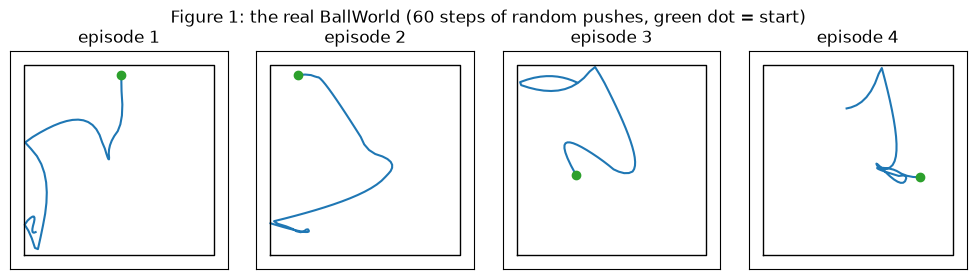

In [4]:
def draw_box(ax, lim=1.15):
    ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], 'k-', lw=1)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

rng_demo = np.random.default_rng(SEED + 1)
S_demo = simulate(true_step, random_states(rng_demo, 4), sticky_actions(rng_demo, 4, 60))

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for i, ax in enumerate(axes):
    ax.plot(S_demo[i, :, 0], S_demo[i, :, 1], '-', lw=1.5)
    ax.plot(S_demo[i, 0, 0], S_demo[i, 0, 1], 'o', color='tab:green')
    draw_box(ax)
    ax.set_title(f'episode {i + 1}')
fig.suptitle('Figure 1: the real BallWorld (60 steps of random pushes, green dot = start)')
plt.tight_layout()
plt.show()

## 2. 收集数据：让小球随便跑

世界模型要从数据里学。我们让 100 个小球各跑 200 步，每一步记下一条**转移** $(s, a, s')$：当前状态、动作、下一个状态。一共 2 万条，用来训练。

再另外跑 25 个小球（5 千条）当验证集。注意验证集是**另外跑出来的完整轨迹**，而不是从 2 万条里随机抽的：同一条轨迹上相邻两步几乎一模一样，如果随机抽，验证集里的样本在训练集里都有"双胞胎"，验证误差就会偏乐观。

In [5]:
def collect(rng, n_env, T):
    ##  让 n_env 个球各跑 T 步，把轨迹拆成一条条转移 (s, a, s')，并标记每条转移有没有碰墙
    A = sticky_actions(rng, n_env, T)
    S = simulate(true_step, random_states(rng, n_env), A)
    s, a, s_next = S[:, :-1].reshape(-1, 4), A.reshape(-1, 2), S[:, 1:].reshape(-1, 4)
    bounced = env_step(s, a)[1]
    return s, a, s_next, bounced

s_tr, a_tr, s2_tr, b_tr = collect(np.random.default_rng(SEED + 10), n_env=100, T=200)
s_va, a_va, s2_va, b_va = collect(np.random.default_rng(SEED + 20), n_env=25, T=200)

if TRAIN_SPEED_LIMIT is not None:   ## 练习 4：只保留低速的训练数据
    keep = np.linalg.norm(s_tr[:, 2:], axis=1) <= TRAIN_SPEED_LIMIT
    s_tr, a_tr, s2_tr, b_tr = s_tr[keep], a_tr[keep], s2_tr[keep], b_tr[keep]

print(f'训练集 {len(s_tr)} 条转移，其中碰墙的占 {b_tr.mean():.1%}')
print(f'验证集 {len(s_va)} 条转移，其中碰墙的占 {b_va.mean():.1%}')

训练集 20000 条转移，其中碰墙的占 6.3%
验证集 5000 条转移，其中碰墙的占 6.9%


## 3. 世界模型：一个预测"下一步"的 MLP

模型的输入是 $(s, a)$，共 6 个数；输出是下一个状态。有两个小技巧：

**技巧 1：预测变化量 $\Delta s = s' - s$，而不是直接预测 $s'$。** 每一步小球只移动一点点，$s'$ 和 $s$ 几乎一样。直接预测 $s'$，网络得先学会"原样抄一遍输入"，再在上面加一个微小的修正；预测 $\Delta s$，网络只需要学那个修正。这和你在 GoogLeNet 里加的**残差连接**是同一个想法：$s' = s + f(s, a)$。

**技巧 2：标准化。** 位置在 $[-1,1]$ 之间，而每一步的位置变化只有零点几，量级差很多。把每个输入、每个输出都减去均值、除以标准差，让它们的量级都在 1 左右，训练会稳定很多。均值和标准差只用**训练集**来算。

另外，这次训练循环我们自己手写，不用 `d2l.train_ch6`，这样每一步都看得见。顺带一提：你在 GoogLeNet notebook 里自己创建的 SGD 优化器（带 momentum 和 weight_decay）其实没有生效——`d2l.train_ch6` 内部会重新创建一个普通的 SGD，还会重新初始化权重。自己写训练循环，就不会有这种"以为用上了其实没用上"的情况。

In [6]:
class WorldModel(nn.Module):
    ##  世界模型：输入当前状态 s 和动作 a，预测下一个状态 s'
    def __init__(self, stats, hidden=256, predict_delta=True):
        super().__init__()
        self.predict_delta = predict_delta
        self.net = nn.Sequential(
            nn.Linear(6, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 4))
        ##  标准化用的均值和标准差存成 buffer：它们不是参数，不参与训练，
        ##  但会跟着 model.to(device) 一起搬到 GPU，也会跟着 state_dict 一起保存
        for name, value in stats.items():
            self.register_buffer(name, torch.as_tensor(value, dtype=torch.float32))

    def forward(self, s, a):
        ##  返回"标准化之后"的输出，训练时直接拿它和标准化后的目标算 MSE
        x = torch.cat([s, a], dim=-1)
        return self.net((x - self.x_mean) / self.x_std)

    def predict(self, s, a):
        ##  返回真实单位下的下一个状态 s'
        y = self.forward(s, a) * self.y_std + self.y_mean
        return s + y if self.predict_delta else y

x_tr = np.concatenate([s_tr, a_tr], axis=1)
y_tr = (s2_tr - s_tr) if PREDICT_DELTA else s2_tr
if NORMALIZE:
    stats = dict(x_mean=x_tr.mean(0), x_std=x_tr.std(0), y_mean=y_tr.mean(0), y_std=y_tr.std(0))
else:
    stats = dict(x_mean=np.zeros(6), x_std=np.ones(6), y_mean=np.zeros(4), y_std=np.ones(4))
print('输出 (dx, dy, dvx, dvy) 各分量的标准差:', np.round(y_tr.std(0), 4))

def to_tensor(x):
    return torch.as_tensor(x, dtype=torch.float32, device=device)   ## numpy 默认 float64，PyTorch 的层要 float32

model = WorldModel(stats, predict_delta=PREDICT_DELTA).to(device)
print(f'模型参数量: {sum(p.numel() for p in model.parameters())}')

输出 (dx, dy, dvx, dvy) 各分量的标准差: [0.0537 0.0548 0.2847 0.2982]
模型参数量: 68612


epoch   1 | train loss 0.46039 | val loss 0.44407


epoch  11 | train loss 0.16548 | val loss 0.18503


epoch  21 | train loss 0.08250 | val loss 0.10737


epoch  31 | train loss 0.05414 | val loss 0.08716


epoch  41 | train loss 0.04402 | val loss 0.07850


epoch  51 | train loss 0.03999 | val loss 0.07797


epoch  60 | train loss 0.03886 | val loss 0.07800
训练用时 13.5 秒


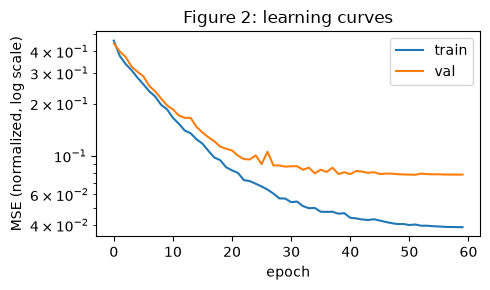

In [7]:
def normalized_target(model, s, s_next):
    y = (s_next - s) if model.predict_delta else s_next
    return (y - model.y_mean) / model.y_std

def train(model, data_tr, data_va, epochs=60, batch_size=256, lr=1e-3):
    s, a, s2 = [to_tensor(x) for x in data_tr]
    s_v, a_v, s2_v = [to_tensor(x) for x in data_va]
    n = s.shape[0]
    steps_per_epoch = (n + batch_size - 1) // batch_size
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ##  学习率按余弦曲线从 lr 慢慢降到 0：前期大步走，后期小步精修
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * steps_per_epoch)
    loss_fn = nn.MSELoss()
    history = {'train': [], 'val': []}
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)   ## 每个 epoch 打乱一次顺序
        total = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            loss = loss_fn(model(s[idx], a[idx]), normalized_target(model, s[idx], s2[idx]))
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(s_v, a_v), normalized_target(model, s_v, s2_v)).item()
        history['train'].append(total / n)
        history['val'].append(val)
        if epoch % 10 == 0 or epoch == epochs - 1:
            print(f'epoch {epoch + 1:3d} | train loss {total / n:.5f} | val loss {val:.5f}')
    return history

t0 = time.time()
history = train(model, (s_tr, a_tr, s2_tr), (s_va, a_va, s2_va))
print(f'训练用时 {time.time() - t0:.1f} 秒')

plt.figure(figsize=(5, 3))
plt.semilogy(history['train'], label='train')
plt.semilogy(history['val'], label='val')
plt.xlabel('epoch')
plt.ylabel('MSE (normalized, log scale)')
plt.title('Figure 2: learning curves')
plt.legend()
plt.tight_layout()
plt.show()

## 4. 单步预测：模型学得怎么样？

先回头看一眼图 2：验证损失停在训练损失上面一截，说明模型有点**过拟合**（6.8 万个参数，只有 2 万条训练数据）。而且损失的大头来自数量很少的碰墙样本，原因下面就会看到。

先看最简单的：给模型一个**真实**的状态和动作，它预测的下一步位置离真实位置差多少？我们特别关心两类转移：**碰墙**的和**不碰墙**的。

验证集单步位置误差：RMSE 0.0082，中位数 0.00174
  不碰墙的转移：误差中位数 0.00163
  碰墙的转移：  误差中位数 0.01328（是不碰墙的 8.1 倍）


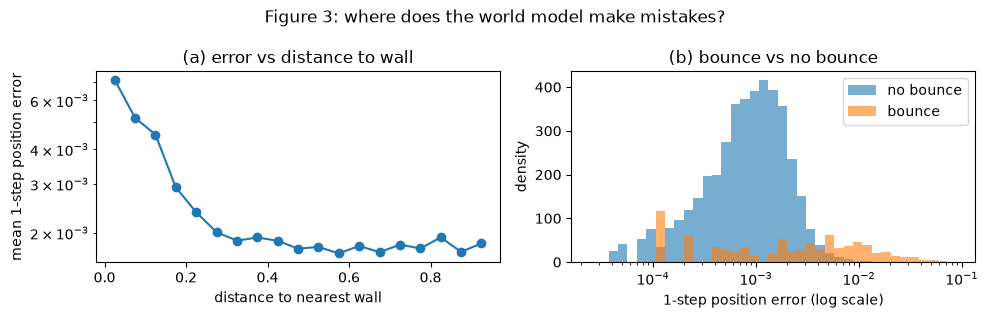

In [8]:
model.eval()
with torch.no_grad():
    pred_va = model.predict(to_tensor(s_va), to_tensor(a_va)).cpu().numpy()
err_1 = np.linalg.norm(pred_va[:, :2] - s2_va[:, :2], axis=1)   ## 每条转移的位置误差
rmse_1 = np.sqrt(np.mean(err_1 ** 2))
med_1 = np.median(err_1)
med_free, med_bounce = np.median(err_1[~b_va]), np.median(err_1[b_va])
print(f'验证集单步位置误差：RMSE {rmse_1:.4f}，中位数 {med_1:.5f}')
print(f'  不碰墙的转移：误差中位数 {med_free:.5f}')
print(f'  碰墙的转移：  误差中位数 {med_bounce:.5f}（是不碰墙的 {med_bounce / med_free:.1f} 倍）')

dist_wall = 1 - np.abs(s_va[:, :2]).max(axis=1)   ## 当前位置离最近的墙有多远
bins = np.linspace(0, 1, 21)
centers, means = [], []
for lo_, hi_ in zip(bins[:-1], bins[1:]):
    m = (dist_wall >= lo_) & (dist_wall < hi_)
    if m.sum() >= 20:
        centers.append((lo_ + hi_) / 2)
        means.append(err_1[m].mean())   ## 用平均值：少数碰墙的大误差会把平均值拉上去，中位数则看不出来

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].semilogy(centers, means, 'o-')
axes[0].set_xlabel('distance to nearest wall')
axes[0].set_ylabel('mean 1-step position error')
axes[0].set_title('(a) error vs distance to wall')
log_bins = np.logspace(np.log10(max(err_1.min(), 1e-6)), np.log10(err_1.max()), 40)
axes[1].hist(err_1[~b_va], bins=log_bins, alpha=0.6, density=True, label='no bounce')
axes[1].hist(err_1[b_va], bins=log_bins, alpha=0.6, density=True, label='bounce')
axes[1].set_xscale('log')
axes[1].set_xlabel('1-step position error (log scale)')
axes[1].set_ylabel('density')
axes[1].set_title('(b) bounce vs no bounce')
axes[1].legend()
fig.suptitle('Figure 3: where does the world model make mistakes?')
plt.tight_layout()
plt.show()

**怎么读这张图**：单步误差整体已经很小了，但它不是均匀分布的——贴着墙的地方平均误差明显更大；碰墙的转移误差明显比不碰墙的大（具体倍数看上面打印的结果）。

原因有两层：

1. **样本少**：除了碰墙，这个世界的规律是线性的，MLP 很容易学；碰墙的样本只占一小部分（看第 2 节打印的比例），模型见得少。
2. **跳变画不出来**：碰墙那一刻，速度会突然反向——差一点点没碰到墙，速度几乎不变；刚好碰到，速度直接变号。这是一个**跳变（不连续）**。而 ReLU 网络表示的函数一定是连续的（本质上是很多段直线拼成的折线），画不出真正的跳变，只能在墙附近用一段很陡的斜坡去近似。所以不管怎么训练，墙边总有一小块区域预测不准。

这是世界模型的一个普遍现象：**模型在"常见又平滑"的地方学得好，在"少见又突变"的地方学得差。** 真实世界里的碰撞、接触、摔倒，恰恰是这种地方。

## 5. 做梦：让世界模型自己往后想象

单步预测时，模型每一步拿到的都是**真实**状态。但真正用世界模型"想象未来"时，没有真实状态可拿：第一步的输出要当成第二步的输入，第二步的输出再当成第三步的输入……这叫**自回归展开（rollout）**，也就是"做梦"。

下面给 300 个起点各配一串随机动作，同一串动作分别在真实世界和世界模型里跑 100 步，比较两条轨迹。注意 `simulate` 函数完全没改：只是把 `true_step` 换成了 `model_step`。

In [9]:
@torch.no_grad()
def model_step(s, a):
    ##  把世界模型包装成和 true_step 一模一样的接口：numpy 进，numpy 出
    return model.predict(to_tensor(s), to_tensor(a)).cpu().numpy().astype(np.float64)

rng_dream = np.random.default_rng(SEED + 2)
N_DREAM, T_DREAM = 300, 100
s0 = random_states(rng_dream, N_DREAM)
A_dream = sticky_actions(rng_dream, N_DREAM, T_DREAM)
S_real = simulate(true_step, s0, A_dream)    ## 真实发生的
S_dream = simulate(model_step, s0, A_dream)  ## 世界模型想象的
err = np.linalg.norm(S_dream[:, :, :2] - S_real[:, :, :2], axis=2)   ## (300, 101)：每一步的位置误差

over = err > 0.1
first_over = np.where(over.any(axis=1), over.argmax(axis=1), T_DREAM + 1)
for t in (1, 10, 50, 100):
    print(f'第 {t:3d} 步：位置误差中位数 {np.median(err[:, t]):.4f}')
print(f'误差第一次超过 0.1 的步数（中位数）：{np.median(first_over):.0f}')
print(f'第 50 步的误差中位数是单步误差中位数的 {np.median(err[:, 50]) / med_1:.0f} 倍')
n_escape = np.sum(np.abs(S_dream[:, :, :2]).max(axis=(1, 2)) > 1.01)
print(f'{N_DREAM} 个梦里，有 {n_escape} 个梦中的球跑出过盒子')

第   1 步：位置误差中位数 0.0026
第  10 步：位置误差中位数 0.0786
第  50 步：位置误差中位数 0.3324
第 100 步：位置误差中位数 0.3089
误差第一次超过 0.1 的步数（中位数）：12
第 50 步的误差中位数是单步误差中位数的 191 倍
300 个梦里，有 216 个梦中的球跑出过盒子


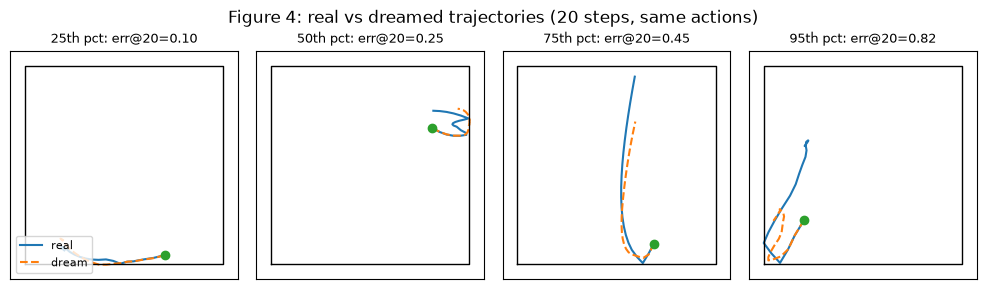

In [10]:
T_SHOW = 20
order = np.argsort(err[:, T_SHOW])
quantiles = (0.25, 0.5, 0.75, 0.95)
picks = [order[int(q * (N_DREAM - 1))] for q in quantiles]   ## 按误差的分位数挑，不专挑好看的
lim = max(1.15, min(3.0, 1.05 * np.abs(S_dream[picks, :T_SHOW + 1, :2]).max()))

fig, axes = plt.subplots(1, 4, figsize=(10, 2.9))
for ax, i, q in zip(axes, picks, quantiles):
    ax.plot(S_real[i, :T_SHOW + 1, 0], S_real[i, :T_SHOW + 1, 1], '-', lw=1.5, label='real')
    ax.plot(S_dream[i, :T_SHOW + 1, 0], S_dream[i, :T_SHOW + 1, 1], '--', lw=1.5, label='dream')
    ax.plot(S_real[i, 0, 0], S_real[i, 0, 1], 'o', color='tab:green')
    draw_box(ax, lim)
    ax.set_title(f'{int(q * 100)}th pct: err@{T_SHOW}={err[i, T_SHOW]:.2f}', fontsize=9)
axes[0].legend(loc='lower left', fontsize=8)
fig.suptitle(f'Figure 4: real vs dreamed trajectories ({T_SHOW} steps, same actions)')
plt.tight_layout()
plt.show()

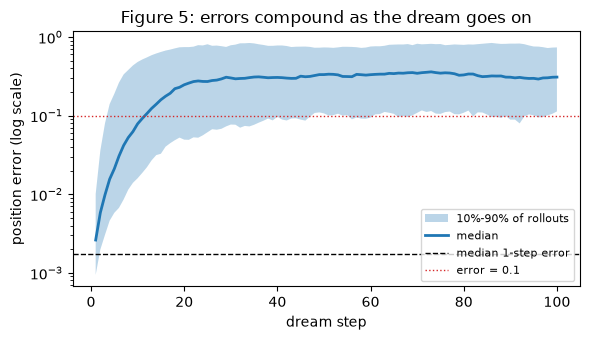

In [11]:
steps = np.arange(1, T_DREAM + 1)
plt.figure(figsize=(6, 3.5))
plt.fill_between(steps, np.percentile(err[:, 1:], 10, axis=0), np.percentile(err[:, 1:], 90, axis=0),
                 alpha=0.3, label='10%-90% of rollouts')
plt.plot(steps, np.median(err[:, 1:], axis=0), lw=2, label='median')
plt.axhline(med_1, color='k', ls='--', lw=1, label='median 1-step error')
plt.axhline(0.1, color='tab:red', ls=':', lw=1, label='error = 0.1')
plt.yscale('log')
plt.xlabel('dream step')
plt.ylabel('position error (log scale)')
plt.title('Figure 5: errors compound as the dream goes on')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

**这是本课最重要的一张图。** 每一步的误差都很小，但做梦时误差会一步步**累积**：第 $t$ 步的小错误变成第 $t+1$ 步的错误输入，模型又在错误的起点上再犯新的错误。结果就是误差随步数迅速变大（看上面打印的"第 50 步是单步的多少倍"）。这叫**误差累积（compounding error）**。

误差涨到一定程度就不再涨了。这不是模型变准了，而是梦和现实已经完全没关系了：两个球都在盒子里，距离最多也就那么大。

再看图 4：有的梦和现实几乎重合，有的在某次碰墙之后就"分岔"了——碰墙时一点点位置或速度的偏差，会让之后的轨迹完全不同。梦里的球还经常**穿墙跑出盒子**（看上面打印的数量）：模型从来没见过盒子外面的数据，不知道那里不该有球。

几乎所有世界模型都要和误差累积作斗争。后面的课会看到几种对策：只往前想有限的几步（本课第 6 节）、在规划时不断用真实观测纠正（本课第 6 节）、在潜空间里做预测（第 6、8 课）、训练时直接优化多步误差（练习 6）。

## 6. 用世界模型做规划：在脑子里试，挑最好的执行

现在给智能体一个任务：**把静止的小球推到目标点，并停在那里**，一共 50 步。智能体不知道物理公式，手里只有刚学会的世界模型。

它用的方法叫**随机射击模型预测控制（random-shooting MPC）**，每一步都做三件事：

1. **想象**：随机生成 $K$ 条动作序列，每条 $H$ 步长，用世界模型想象每条序列会让球怎么走；
2. **打分**：每条想象的轨迹，把未来 $H$ 步离目标的距离平方加起来，越小越好；
3. **执行**：挑出最好的那条，**只执行它的第一个动作**；到了下一步，根据真实的新状态重新想象一遍。

第 3 步很关键：每一步都用真实状态重新规划，梦只需要准 $H$ 步，而且梦里的偏差每一步都会被现实纠正。这正是对付误差累积的办法。

注意 `plan_random_shooting` 只认一个 `step_fn`：传入 `true_step` 就是"拿真实世界来试"（现实中做不到，这里只当作参照），传入 `model_step` 就是"在脑子里试"。**规划器本身分不清梦和现实。**

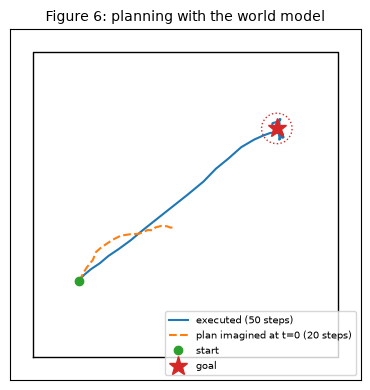

最终离目标 0.029，最终速度 0.234


In [12]:
def plan_random_shooting(step_fn, s, goal, rng, K=K, H=H):
    ##  随机射击：在 step_fn 里试 K 条长度为 H 的随机动作序列，挑出离目标最近的那条
    ##  返回：这条序列的第一个动作 (2,)，以及它想象中的轨迹 (H+1, 4)
    A = rng.uniform(-1, 1, size=(K, H, 2))
    S = simulate(step_fn, np.repeat(s[None], K, axis=0), A)   ## (K, H+1, 4)：K 个想象中的未来
    cost = np.sum((S[:, 1:, :2] - goal) ** 2, axis=(1, 2))    ## 未来 H 步离目标的距离平方之和
    best = np.argmin(cost)
    return A[best, 0], S[best]

def make_mpc_policy(step_fn, seed):
    rng = np.random.default_rng(seed)
    return lambda s, goal: plan_random_shooting(step_fn, s, goal, rng)[0]

def make_random_policy(seed):
    rng = np.random.default_rng(seed)
    return lambda s, goal: rng.uniform(-1, 1, size=2)

def run_episode(policy, s0, goal, T=50):
    ##  动作永远在真实世界里执行，世界模型只用来"想"
    s, path = s0.copy(), [s0.copy()]
    for t in range(T):
        a = policy(s, goal)
        s = true_step(s[None], a[None])[0]
        path.append(s)
    return np.array(path)

## 一个例子：看看 t=0 时智能体脑子里的计划，和它实际走出来的路线
s_start, goal = np.array([-0.7, -0.5, 0.0, 0.0]), np.array([0.6, 0.5])
_, imagined = plan_random_shooting(model_step, s_start, goal, np.random.default_rng(SEED + 5))
path = run_episode(make_mpc_policy(model_step, SEED + 5), s_start, goal)

plt.figure(figsize=(4, 4))
ax = plt.gca()
ax.plot(path[:, 0], path[:, 1], '-', lw=1.5, label='executed (50 steps)')
ax.plot(imagined[:, 0], imagined[:, 1], '--', lw=1.5, label=f'plan imagined at t=0 ({H} steps)')
ax.plot(*s_start[:2], 'o', color='tab:green', label='start')
ax.plot(*goal, '*', color='tab:red', ms=14, label='goal')
circle = plt.Circle(goal, 0.1, color='tab:red', fill=False, ls=':')
ax.add_patch(circle)
draw_box(ax)
ax.legend(loc='lower right', fontsize=7)
ax.set_title('Figure 6: planning with the world model', fontsize=10)
plt.tight_layout()
plt.show()
print(f'最终离目标 {np.linalg.norm(path[-1, :2] - goal):.3f}，最终速度 {np.linalg.norm(path[-1, 2:]):.3f}')

图 6 里有个有意思的对比：t=0 时想出来的计划（虚线）歪歪扭扭，只是随机试出来的"还不错"的一条；但因为每一步都根据真实状态重新规划，实际走出的路线（实线）又直又稳。**计划本身不用完美，不断重新规划就行。**

### 三个控制器比一比

同样 20 组（起点，目标），比较三种做法。成功的标准是：50 步之后，小球离目标不到 0.1。

| 控制器 | 做法 |
|---|---|
| `random` | 每一步随便推一下 |
| `MPC + real simulator` | 拿**真实世界**来试动作（现实中做不到，只当作上限参照） |
| `MPC + world model` | 拿**学到的世界模型**来试动作 |

后两个用的随机数完全一样，唯一的区别是"在哪里试"。

random                 | 成功率    0% | 平均最终距离 1.073 | 每回合用时 0.00 秒


MPC + real simulator   | 成功率  100% | 平均最终距离 0.041 | 每回合用时 0.08 秒


MPC + world model      | 成功率  100% | 平均最终距离 0.043 | 每回合用时 0.59 秒


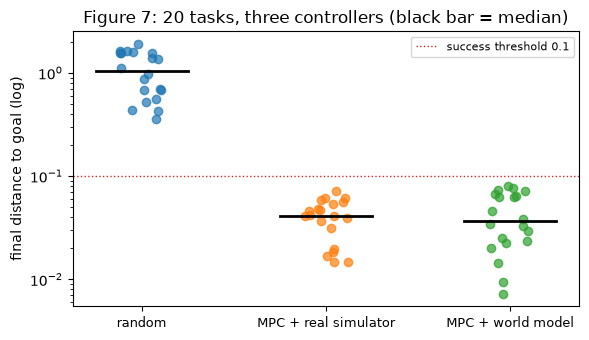

[SUMMARY] rmse_1step=0.0082 bounce_over_free=8.1 dream50_over_1step=191 success_random=0% success_oracle=100% success_model=100% runtime=30s


In [13]:
rng_task = np.random.default_rng(SEED + 3)
N_TASK, T_EP = 20, 50
starts = np.concatenate([rng_task.uniform(-0.9, 0.9, size=(N_TASK, 2)), np.zeros((N_TASK, 2))], axis=1)   ## 从静止开始
goals = rng_task.uniform(-0.7, 0.7, size=(N_TASK, 2))

controllers = {
    'random': lambda i: make_random_policy(SEED + 100 + i),
    'MPC + real simulator': lambda i: make_mpc_policy(true_step, SEED + 200 + i),
    'MPC + world model': lambda i: make_mpc_policy(model_step, SEED + 200 + i),
}
final_dist, success = {}, {}
for name, make_policy in controllers.items():
    t0 = time.time()
    d = []
    for i in range(N_TASK):
        path = run_episode(make_policy(i), starts[i], goals[i], T_EP)
        d.append(np.linalg.norm(path[-1, :2] - goals[i]))
    final_dist[name] = np.array(d)
    success[name] = np.mean(final_dist[name] < 0.1)
    print(f'{name:22s} | 成功率 {success[name]:5.0%} | 平均最终距离 {final_dist[name].mean():.3f} '
          f'| 每回合用时 {(time.time() - t0) / N_TASK:.2f} 秒')

plt.figure(figsize=(6, 3.5))
rng_jitter = np.random.default_rng(0)
for j, (name, d) in enumerate(final_dist.items()):
    x = j + rng_jitter.uniform(-0.12, 0.12, size=len(d))
    plt.scatter(x, np.maximum(d, 1e-3), alpha=0.7)
    plt.plot([j - 0.25, j + 0.25], [np.median(d)] * 2, 'k-', lw=2)
plt.axhline(0.1, color='tab:red', ls=':', lw=1, label='success threshold 0.1')
plt.yscale('log')
plt.xticks(range(len(final_dist)), list(final_dist.keys()), fontsize=9)
plt.ylabel('final distance to goal (log)')
plt.title('Figure 7: 20 tasks, three controllers (black bar = median)')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f'[SUMMARY] rmse_1step={rmse_1:.4f} bounce_over_free={med_bounce / med_free:.1f} '
      f'dream50_over_1step={np.median(err[:, 50]) / med_1:.0f} '
      f"success_random={success['random']:.0%} success_oracle={success['MPC + real simulator']:.0%} "
      f"success_model={success['MPC + world model']:.0%} runtime={time.time() - T_START:.0f}s")

**结果怎么看**：随机乱推几乎不可能成功；用学到的世界模型规划，成功率和"拿真实世界来试"的参照差不多（具体数字看上面的输出）。也就是说：**智能体没有学过任何控制策略，只学了一个"世界怎么变"的模型，就能在脑子里把事情想清楚再动手。**

说句实话：这个任务本身很简单，手工调一个 PD 控制器也能做到。本课的重点不是"解决了一个难题"，而是规划器**只用了学到的模型**，没有用任何物理公式。到了后面的课，世界从 4 个数变成一张张图片，没有人写得出 PD 控制器，这套"先学世界、再在脑子里规划"的思路依然管用。

## 7. 总结

### 本课的"世界模型成绩单"

以后每一课都会用这四项来评价世界模型：

| 指标 | 本课测的是什么 | 看哪里 |
|---|---|---|
| 单步误差 | 给真实状态，预测下一步准不准 | 第 4 节的输出、图 3 |
| 多步误差 | 自己做梦，误差随步数怎么增长 | 第 5 节的输出、图 5 |
| 控制效果 | 只靠模型规划，任务能不能完成 | 第 6 节的输出、图 7 |
| 被钻空子 | 规划器会不会专挑模型出错的地方 | 本课的简单任务里还看不到，练习 4 讨论为什么；第 2 课会正面遇到 |

### 三个要点

1. **世界模型 = 预测"做了某个动作之后，世界会变成什么样"的模型**，这里就是一个输入 $(s,a)$、输出 $s'$ 的 MLP。
2. **单步准不等于多步准**：做梦时误差会累积，突变的地方（碰墙）最容易出错。
3. **有了世界模型就能规划**：在脑子里试很多动作序列，挑最好的执行，每一步用真实观测重新规划。

### 本课回避掉的难点，后面的课会一个个解决

| 难点 | 本课为什么没遇到 | 在哪课解决 |
|---|---|---|
| 部分可观测：只看到位置，看不到速度 | 我们直接把速度给了模型 | 第 3 课（RNN 记忆） |
| 高维观测：只看到图像 | 我们直接给了 4 个数 | 第 4 课（VAE 压缩） |
| 随机性：同样的动作，结果不确定 | 这个世界是确定性的 | 第 2、5 课 |
| 策略专钻模型的空子 | 训练数据覆盖了所有情况，任务也简单 | 第 2、5 课 |

练习题在讲义 [README.md](README.md) 的最后。做完练习就可以进入第 1 课了。